In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
import os

tf.keras.utils.disable_interactive_logging()


In [3]:
(x_train, _), (_, _) = mnist.load_data()

x_train = x_train.reshape(x_train.shape[0], 28, 28, 1).astype("float32")
x_train = (x_train - 127.5) / 127.5

print("Normalized training data shape:", x_train.shape)
print("Example normalized pixel value:", x_train[0, 0, 0, 0])


Normalized training data shape: (60000, 28, 28, 1)
Example normalized pixel value: -1.0


In [4]:
latent_dim = 100

def build_generator():
    model = keras.Sequential(name="generator")

    model.add(layers.Input(shape=(latent_dim,)))
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7, 7, 256)))

    model.add(layers.Conv2DTranspose(
        128, (5, 5),
        strides=(1, 1),
        padding="same",
        use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(
        1, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False,
        activation="tanh"
    ))

    return model

generator = build_generator()
generator.summary()

In [5]:
def build_discriminator():
    model = keras.Sequential(name="discriminator")

    model.add(layers.Input(shape=(28, 28, 1)))

    model.add(layers.Conv2D(
        64, (5, 5),
        strides=(2, 2),
        padding="same"
    ))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(
        128, (5, 5),
        strides=(2, 2),
        padding="same"
    ))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation="sigmoid"))

    return model

discriminator = build_discriminator()
discriminator.summary()

In [6]:
cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=False
)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output)

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output)

    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

In [7]:
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4)


In [8]:
batch_size = 256

@tf.function
def train_step(images):
    noise = tf.random.normal(
        [batch_size, latent_dim])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise, training=True)

        real_output = discriminator(
            images, training=True)

        fake_output = discriminator(
            generated_images, training=True)

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables)

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables)

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator,
            generator.trainable_variables))

    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator,
            discriminator.trainable_variables))

    return gen_loss, disc_loss


In [9]:
def generate_and_save_images(model, epoch, test_input):

    predictions = model(
        test_input, training=False)

    predictions = (predictions * 0.5) + 0.5

    fig = plt.figure(figsize=(4, 4))

    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap="gray")

        plt.axis("off")

    plt.suptitle(
        f"Epoch {epoch}",
        fontsize=16)

    if not os.path.exists("images"):
        os.makedirs("images")

    plt.savefig(
        f"images/image_at_epoch_{epoch:04d}.png")

    plt.show()



In [10]:
EPOCHS = 50
num_examples_to_generate = 16

seed = tf.random.normal(
    [num_examples_to_generate, latent_dim])

train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train
).shuffle(
    x_train.shape[0]
).batch(batch_size)


--- Beginning GAN Training ---
Epoch 1/50 - Generator Loss: 0.6479, Discriminator Loss: 1.2231
Epoch 2/50 - Generator Loss: 0.8022, Discriminator Loss: 1.2623
Epoch 3/50 - Generator Loss: 0.8340, Discriminator Loss: 1.2473
Epoch 4/50 - Generator Loss: 0.7496, Discriminator Loss: 1.3589
Epoch 5/50 - Generator Loss: 0.7437, Discriminator Loss: 1.3730
Epoch 6/50 - Generator Loss: 0.8072, Discriminator Loss: 1.2907
Epoch 7/50 - Generator Loss: 0.8585, Discriminator Loss: 1.2687
Epoch 8/50 - Generator Loss: 0.9042, Discriminator Loss: 1.2230
Epoch 9/50 - Generator Loss: 0.9846, Discriminator Loss: 1.1715
Epoch 10/50 - Generator Loss: 0.9386, Discriminator Loss: 1.2045
Epoch 11/50 - Generator Loss: 0.9722, Discriminator Loss: 1.1736
Epoch 12/50 - Generator Loss: 0.9712, Discriminator Loss: 1.1762
Epoch 13/50 - Generator Loss: 1.0332, Discriminator Loss: 1.1365
Epoch 14/50 - Generator Loss: 1.0554, Discriminator Loss: 1.1683
Epoch 15/50 - Generator Loss: 1.0535, Discriminator Loss: 1.1029
Epo

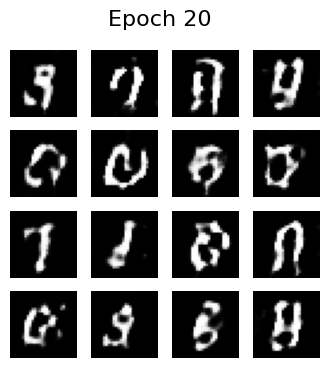

Epoch 21/50 - Generator Loss: 1.1640, Discriminator Loss: 1.0375
Epoch 22/50 - Generator Loss: 1.1886, Discriminator Loss: 1.0807
Epoch 23/50 - Generator Loss: 1.2531, Discriminator Loss: 1.0123
Epoch 24/50 - Generator Loss: 1.2604, Discriminator Loss: 1.0378
Epoch 25/50 - Generator Loss: 1.2291, Discriminator Loss: 1.0643
Epoch 26/50 - Generator Loss: 1.2818, Discriminator Loss: 1.0206
Epoch 27/50 - Generator Loss: 1.1760, Discriminator Loss: 1.1034
Epoch 28/50 - Generator Loss: 1.2144, Discriminator Loss: 1.0691
Epoch 29/50 - Generator Loss: 1.1829, Discriminator Loss: 1.1314
Epoch 30/50 - Generator Loss: 1.1884, Discriminator Loss: 1.0961
Epoch 31/50 - Generator Loss: 1.1020, Discriminator Loss: 1.1368
Epoch 32/50 - Generator Loss: 1.0638, Discriminator Loss: 1.1645
Epoch 33/50 - Generator Loss: 1.0444, Discriminator Loss: 1.1857
Epoch 34/50 - Generator Loss: 1.0572, Discriminator Loss: 1.1831
Epoch 35/50 - Generator Loss: 1.0364, Discriminator Loss: 1.1748
Epoch 36/50 - Generator L

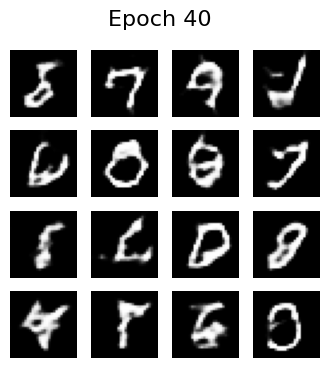

Epoch 41/50 - Generator Loss: 0.9621, Discriminator Loss: 1.2093
Epoch 42/50 - Generator Loss: 1.0075, Discriminator Loss: 1.2135
Epoch 43/50 - Generator Loss: 1.0172, Discriminator Loss: 1.1892
Epoch 44/50 - Generator Loss: 1.0166, Discriminator Loss: 1.1956
Epoch 45/50 - Generator Loss: 0.9562, Discriminator Loss: 1.2143
Epoch 46/50 - Generator Loss: 0.9302, Discriminator Loss: 1.2399
Epoch 47/50 - Generator Loss: 0.9570, Discriminator Loss: 1.2192
Epoch 48/50 - Generator Loss: 0.9593, Discriminator Loss: 1.2141
Epoch 49/50 - Generator Loss: 0.9484, Discriminator Loss: 1.2310
Epoch 50/50 - Generator Loss: 0.9584, Discriminator Loss: 1.2218
--- Training complete. Generating final images. ---


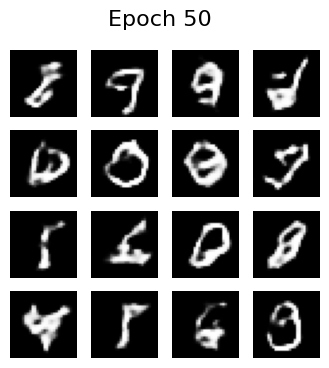

In [11]:
def train(dataset, epochs):

    print("--- Beginning GAN Training ---")

    for epoch in range(epochs):

        gen_loss_list = []
        disc_loss_list = []

        for image_batch in dataset:

            gen_loss, disc_loss = train_step(
                image_batch)

            gen_loss_list.append(
                gen_loss.numpy())

            disc_loss_list.append(
                disc_loss.numpy())

        avg_gen_loss = np.mean(gen_loss_list)
        avg_disc_loss = np.mean(disc_loss_list)

        print(
            f"Epoch {epoch + 1}/{epochs} - "
            f"Generator Loss: {avg_gen_loss:.4f}, "
            f"Discriminator Loss: {avg_disc_loss:.4f}"
        )

        if (epoch + 1) % 20 == 0:
            generate_and_save_images(
                generator,
                epoch + 1,
                seed)

    print(
        "--- Training complete. "
        "Generating final images. ---"
    )

    generate_and_save_images(
        generator,
        epochs,
        seed)


# Run training
train(train_dataset, EPOCHS)